In [1]:
import pandas as pd
import numpy as np

In [6]:
df = pd.read_csv('placement.csv')

In [7]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [8]:
df.shape

(100, 4)

In [9]:
df= df.iloc[:,1:]

In [11]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [13]:
import matplotlib.pyplot as plt

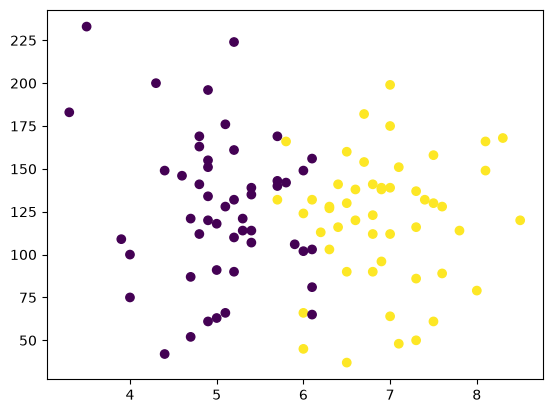

In [16]:
plt.scatter(df['cgpa'],df['iq'] , c = df['placement'])

In [20]:
X = df.iloc[:,0:2]
Y = df.iloc[:,-1]

In [21]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [22]:
Y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [25]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X,y,test_size=0.1)

In [26]:
x_train

,cgpa,iq
81,5.4,107.0
20,6.6,120.0
57,6.5,130.0
62,6.0,102.0
5,7.1,48.0
...,...,...
18,4.0,100.0
37,8.1,149.0
45,6.0,66.0
35,6.8,90.0


In [27]:
y_train

81    0
20    1
57    1
62    0
5     1
     ..
18    0
37    1
45    1
35    1
48    1
Name: placement, Length: 90, dtype: int64

In [28]:
x_test

,cgpa,iq
30,7.6,128.0
78,6.1,81.0
95,4.3,200.0
9,5.1,66.0
75,4.8,169.0
60,6.9,139.0
21,7.1,151.0
40,4.9,134.0
67,5.0,118.0
79,6.5,90.0


In [29]:
y_test

30    1
78    0
95    0
9     0
75    0
60    1
21    1
40    0
67    0
79    1
Name: placement, dtype: int64

In [32]:
from sklearn.preprocessing import StandardScaler

In [36]:
scaler = StandardScaler()

In [39]:
x_train = scaler.fit_transform(x_train)

In [40]:
x_train

array([[-0.53336371, -0.40526236],
       [ 0.51779105, -0.07870798],
       [ 0.43019482,  0.1724877 ],
       [-0.00778633, -0.5308602 ],
       [ 0.95577219, -1.88731685],
       [ 0.69298351, -0.27966452],
       [-1.05894109,  1.00143343],
       [-0.97134486,  0.69999862],
       [-1.14653732, -1.78683858],
       [-0.00778633, -1.96267555],
       [ 0.25500236,  0.12224856],
       [-0.53336371,  0.29808554],
       [ 0.86817596, -0.27966452],
       [-0.70855617,  0.95119429],
       [ 0.16740613, -0.25454495],
       [-0.70855617, -0.83229501],
       [ 0.78057973, -0.6815776 ],
       [-0.00778633,  0.64975948],
       [-0.00778633,  0.02177029],
       [-0.62095994, -0.22942538],
       [ 0.25500236,  0.09712899],
       [-0.09538256, -0.43038193],
       [ 0.69298351,  0.44880294],
       [-1.40932601, -2.03803425],
       [ 0.0798099 ,  0.22272683],
       [ 1.21856088,  0.22272683],
       [ 1.13096465, -0.17918625],
       [ 1.74413826, -1.10861025],
       [-1.05894109,

In [44]:
x_test = scaler.fit_transform(x_test)

In [45]:
x_test

array([[ 1.62248817,  0.01027792],
       [ 0.2474982 , -1.19737781],
       [-1.40248977,  1.86030372],
       [-0.66916179, -1.58279985],
       [-0.94415978,  1.06376484],
       [ 0.98082618,  0.29292075],
       [ 1.16415818,  0.60125839],
       [-0.85249378,  0.16444674],
       [-0.76082779, -0.24667011],
       [ 0.61416219, -0.96612459]])

In [46]:
from sklearn.linear_model import LogisticRegression

In [51]:
clf = LogisticRegression()

In [52]:
#model training
clf.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [55]:
y_pred = clf.predict(x_test)

In [56]:
y_test

30    1
78    0
95    0
9     0
75    0
60    1
21    1
40    0
67    0
79    1
Name: placement, dtype: int64

In [58]:
from sklearn.metrics import accuracy_score

In [60]:
accuracy_score(y_test,y_pred)

0.9

In [63]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

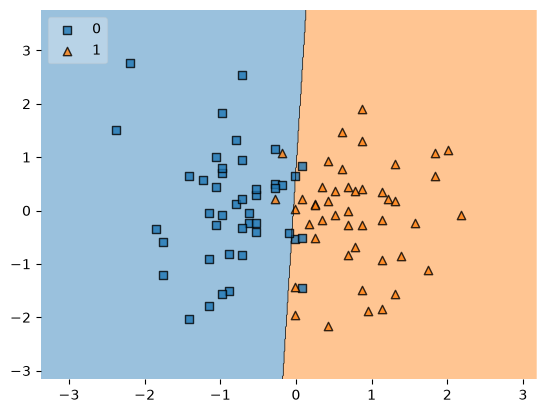

In [65]:
plot_decision_regions(x_train, y_train.values, clf=clf, legend=2)

In [66]:
import pickle

In [69]:
pickle.dump(clf,open('model.pkl','wb'))